In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
from scipy.spatial import cKDTree
import uproot


df = pd.read_csv("cms_table4_ljets.csv")

df["value"] = df["value"] * 1000

data = uproot.concatenate({f: 'tree' for f in [
      'ntuples-mc/TTJets_TuneZ2_7TeV-madgraph-tauola/00000/ttbarSel_merged.root',
      'ntuples-mc/TTJets_TuneZ2_7TeV-madgraph-tauola/00001/ttbarSel_merged.root',
      'ntuples-mc/TTJets_TuneZ2_7TeV-madgraph-tauola/010000/ttbarSel_merged.root',
      'ntuples-mc/TTJets_TuneZ2_7TeV-madgraph-tauola/010001/ttbarSel_merged.root',
      'ntuples-mc/TTJets_TuneZ2_7TeV-madgraph-tauola/010002/ttbarSel_merged.root',
      'ntuples-mc/TTJets_TuneZ2_7TeV-madgraph-tauola/010003/ttbarSel_merged.root',
    ]}, ['mcEventType', 'mcT', 'mcTbar'], library='np')

data_all = np.concatenate([data['mcT'], data['mcTbar']])

n = data_all.shape[0]
n1 = int(n/10)
print(f'Events: {n} -> {n1}')

data_all1 = data_all[:n1].copy()

def nn(x1, x2):
  # найближчий сусід
  tree = cKDTree(x1)
  _, i = tree.query(x2)
  # ваги
  weights = np.bincount(i, minlength=n1)
  sum_x2 = np.zeros_like(x1)
  np.add.at(sum_x2, i, x2)
  #x1_corr = (x1 + sum_x2) / weights[:, None]
  x1_corr = sum_x2 / weights[:, None]
  #for obj in [x1, weights, x1_corr]: print(obj.shape)
  return x1, weights, x1_corr

_, weight, data_all1 = nn(data_all1, data_all)
_, weight, data_all1 = nn(data_all1, data_all)
_, weight, data_all1 = nn(data_all1, data_all)


Events: 6163496 -> 616349
[[ -11.29649099   21.51147461   81.02938334  172.5       ]
 [   9.42204402  -45.39225417  179.92795974  172.5       ]
 [ -59.15465698   54.03518066   73.88127441  172.5       ]
 ...
 [  33.38088829  -96.41101717   33.81390381  172.5       ]
 [ -43.55477397 -181.34419759   -2.00943549  172.5       ]
 [ 149.65606689  -27.0510273  -122.91905975  172.5       ]]
---------------------------
[[ -11.66004639   21.26340904   81.09243927  172.5       ]
 [   9.67032633  -45.38462092  180.24525655  172.5       ]
 [ -59.43921577   54.90155707   73.46322547  172.5       ]
 ...
 [  33.63437822  -96.33080122   33.59392781  172.5       ]
 [ -44.01516019 -181.47944641   -2.21702736  172.5       ]
 [ 150.19736256  -26.42614017 -122.46440843  172.5       ]]
---------------------------
[[ -12.28548412   21.11132431   81.25866699  172.5       ]
 [   9.7588812   -45.3307143   180.42616389  172.5       ]
 [ -59.55543785   55.15315208   73.48969803  172.5       ]
 ...
 [  33.63564951 

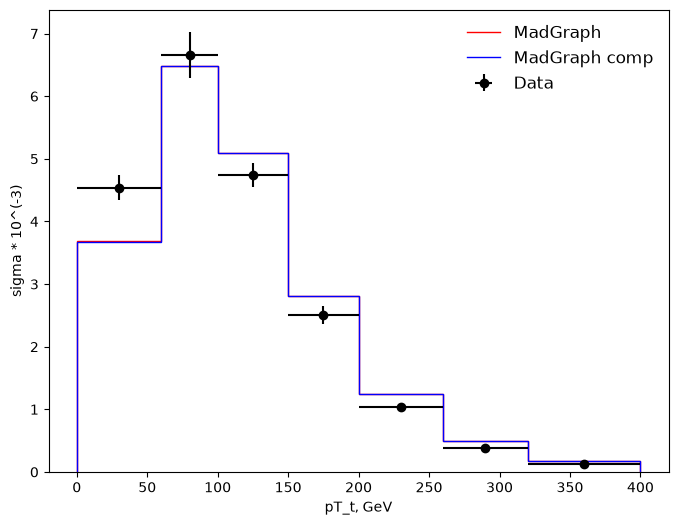

In [46]:
pt = df[df["observable"] == "pT_t"]

#print(pt)

x = (pt["bin_high"] + pt["bin_low"]) / 2
x_err = (pt["bin_high"] - pt["bin_low"]) / 2    

y = pt["value"]
y_total = pt["value"] * (pt["total"]/100)

#Згенеровані данні без стиснення 

data_pT_t = np.sqrt(data_all[:, 0]**2 + data_all[:, 1]**2)

bin = pt['bin_low']
bin = np.append(bin, 400)

bin_width = bin[1:] - bin[:-1]

count, _ = np.histogram(data_pT_t, bins=bin)
data_y = count / (len(data_pT_t) * bin_width)

#Згенеровані дані зі стисненням
data_pT_t_comp = np.sqrt(data_all1[:, 0]**2 + data_all1[:, 1]**2)

count_comp, _ = np.histogram(data_pT_t_comp, bins=bin, weights=weight)
data_y_comp = count_comp / (np.sum(weight) * bin_width)


#Побудова графіків
fig, ax = plt.subplots(figsize=(8, 6))

ax.set_xlabel("pT_t, GeV")
ax.set_ylabel("sigma * 10^(-3)")

#Побудова точок зі статті
ax.errorbar(x, y, xerr=x_err, yerr=y_total, fmt='o', color='black', capsize=0, label='Data')

#Побудова MadGraph
ax.stairs(data_y * 1000, bin, color='red', label='MadGraph')

#Побудова стиснений MadGraph
ax.stairs(data_y_comp * 1000, bin, color='blue', label='MadGraph comp')


ax.legend(loc='upper right', frameon=False, fontsize=12)